In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:

df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:

# 1. Dataset dimensions
print("Dataset shape:", df.shape)

# 2. Column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Data types and missing values
print("\nDataset information:")
df.info()

# 4. Statistical summary
print("\nNumerical summary:")
display(df.describe().T)


Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Numerical summary:


,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303


In [6]:

# 1. Missing values
print("Missing values in each column:")
display(df.isnull().sum())

# 2. Duplicate records
print("\nExact duplicate rows:", df.duplicated().sum())

# 3. Cancelled invoices
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
print("Rows with cancellation invoice numbers:", cancelled.sum())

# 4. Negative quantities
print("Rows with negative quantities:", (df["Quantity"] < 0).sum())

# 5. Zero or negative prices
print("Rows with zero prices:", (df["UnitPrice"] == 0).sum())
print("Rows with negative prices:", (df["UnitPrice"] < 0).sum())

# 6. Date range
print("\nEarliest invoice date:", df["InvoiceDate"].min())
print("Latest invoice date:", df["InvoiceDate"].max())


Missing values in each column:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Exact duplicate rows: 5268
Rows with cancellation invoice numbers: 9288
Rows with negative quantities: 10624
Rows with zero prices: 2515
Rows with negative prices: 2

Earliest invoice date: 2010-12-01 08:26:00
Latest invoice date: 2011-12-09 12:50:00


In [7]:

# Keep the original dataset unchanged
df_clean = df.copy()

# 1. Remove exact duplicate rows
duplicates_before = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().copy()

# 2. Remove rows with missing product descriptions
# Keep rows with missing CustomerID for general sales analysis
missing_descriptions = df_clean["Description"].isna().sum()
df_clean = df_clean.dropna(subset=["Description"]).copy()

# 3. Ensure correct data types
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"], errors="coerce"
)

df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"], errors="coerce"
)

df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"], errors="coerce"
)

# 4. Create a revenue column
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# 5. Review cleaning results
print("Original rows:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Duplicates removed:", duplicates_before)
print("Missing descriptions before removal:", missing_descriptions)

print("\nMissing values after cleaning:")
display(df_clean.isnull().sum())

print("\nRemaining negative quantities:", (df_clean["Quantity"] < 0).sum())
print("Remaining zero prices:", (df_clean["UnitPrice"] == 0).sum())
print("Remaining negative prices:", (df_clean["UnitPrice"] < 0).sum())


Original rows: 541909
Rows after cleaning: 535187
Duplicates removed: 5268
Missing descriptions before removal: 1454

Missing values after cleaning:


InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     133583
Country             0
Revenue             0
dtype: int64


Remaining negative quantities: 9725
Remaining zero prices: 1056
Remaining negative prices: 2


In [8]:

# Identify cancelled invoices
is_cancelled = (
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
)

# Keep valid positive sales transactions
df_sales = df_clean.loc[
    (~is_cancelled)
    & (df_clean["Quantity"] > 0)
    & (df_clean["UnitPrice"] > 0)
].copy()

# Check the result
print("Sales dataset shape:", df_sales.shape)
print("Unique invoices:", df_sales["InvoiceNo"].nunique())
print("Unique products:", df_sales["StockCode"].nunique())
print("Unique countries:", df_sales["Country"].nunique())
print("Total sales revenue:", round(df_sales["Revenue"].sum(), 2))


Sales dataset shape: (524878, 9)
Unique invoices: 19960
Unique products: 3922
Unique countries: 38
Total sales revenue: 10642110.8


In [9]:

# Calculate revenue generated by each product
top_products = (
    df_sales.groupby(["StockCode", "Description"])["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

print("Top 10 products by revenue:")
display(top_products)


Top 10 products by revenue:


,StockCode,Description,Revenue
0,DOT,DOTCOM POSTAGE,206248.77
1,22423,REGENCY CAKESTAND 3 TIER,174156.54
2,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24
4,47566,PARTY BUNTING,99445.23
5,85099B,JUMBO BAG RED RETROSPOT,94159.81
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POST,POSTAGE,78101.88
8,M,Manual,77750.27
9,23084,RABBIT NIGHT LIGHT,66870.03


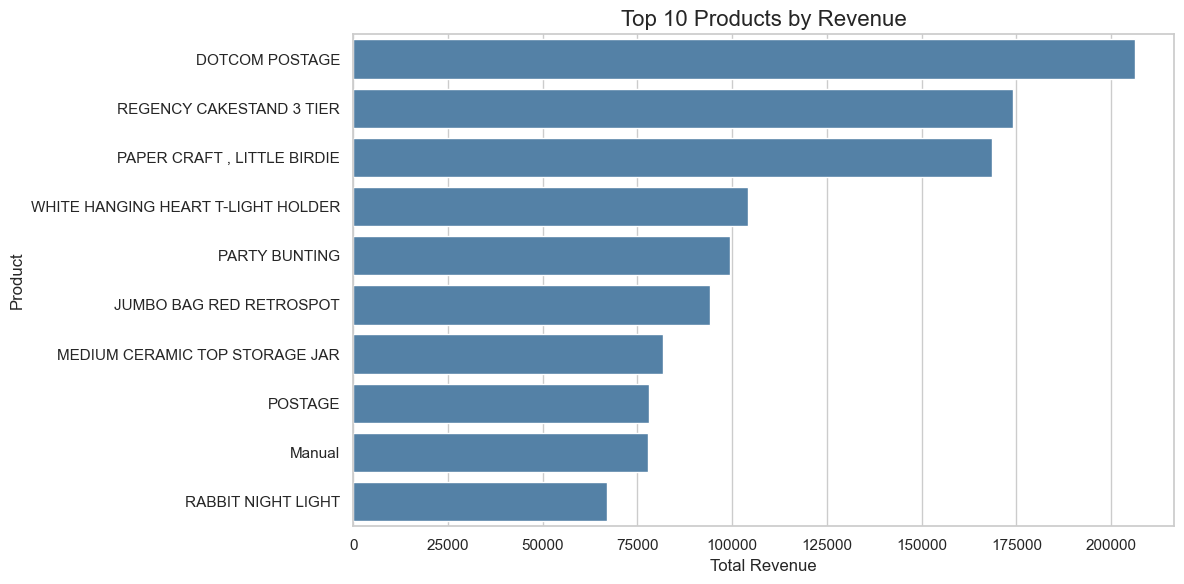

In [10]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x="Revenue",
    y="Description",
    color="steelblue"
)

plt.title("Top 10 Products by Revenue", fontsize=16)
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


Observation: DOTCOM POSTAGE generated the highest recorded revenue at approximately 206,249, followed by REGENCY CAKESTAND 3 TIER at 174,157 and PAPER CRAFT, LITTLE BIRDIE at 168,470. Postage and manual entries also appear among the top 10, so these should be distinguished from physical merchandise when evaluating product performance.

In [13]:

# Calculate revenue by country
country_revenue = (
    df_sales.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

print("Top 10 countries by revenue:")
display(country_revenue)


Top 10 countries by revenue:


,Country,Revenue
0,United Kingdom,9001744.094
1,Netherlands,285446.340
2,EIRE,283140.520
3,Germany,228678.400
4,France,209625.370
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,57067.600
8,Belgium,41196.340
9,Sweden,38367.830


Observation: The United Kingdom generated the highest revenue, approximately 9.00 million, substantially exceeding every other country. The Netherlands and EIRE followed with approximately 285,446 and 283,141, respectively. This indicates that the business's revenue is heavily concentrated in the UK market.

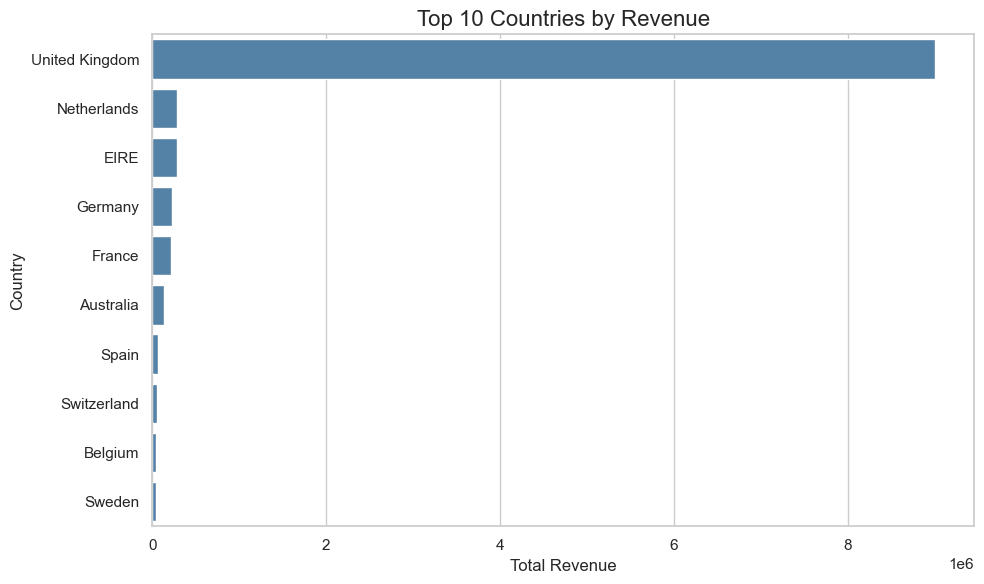

In [14]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=country_revenue,
    x="Revenue",
    y="Country",
    color="steelblue"
)

plt.title("Top 10 Countries by Revenue", fontsize=16)
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


###Observation: The United Kingdom generated approximately 9.00 million in revenue, far exceeding the Netherlands (285,446) and EIRE (283,141). The business relies heavily on the UK market, suggesting an opportunity to strengthen marketing and customer acquisition in other countries.

In [15]:

# Extract month from invoice date
df_sales["Month"] = df_sales["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = (
    df_sales.groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)

# Convert month to timestamp for plotting
monthly_sales["Month"] = monthly_sales["Month"].dt.to_timestamp()

print("Monthly revenue:")
display(monthly_sales)


Monthly revenue:


,Month,Revenue
0,2010-12-01,821452.730
1,2011-01-01,689811.610
2,2011-02-01,522545.560
3,2011-03-01,716215.260
4,2011-04-01,536968.491
5,2011-05-01,769296.610
6,2011-06-01,760547.010
7,2011-07-01,718076.121
8,2011-08-01,757841.380
9,2011-09-01,1056435.192


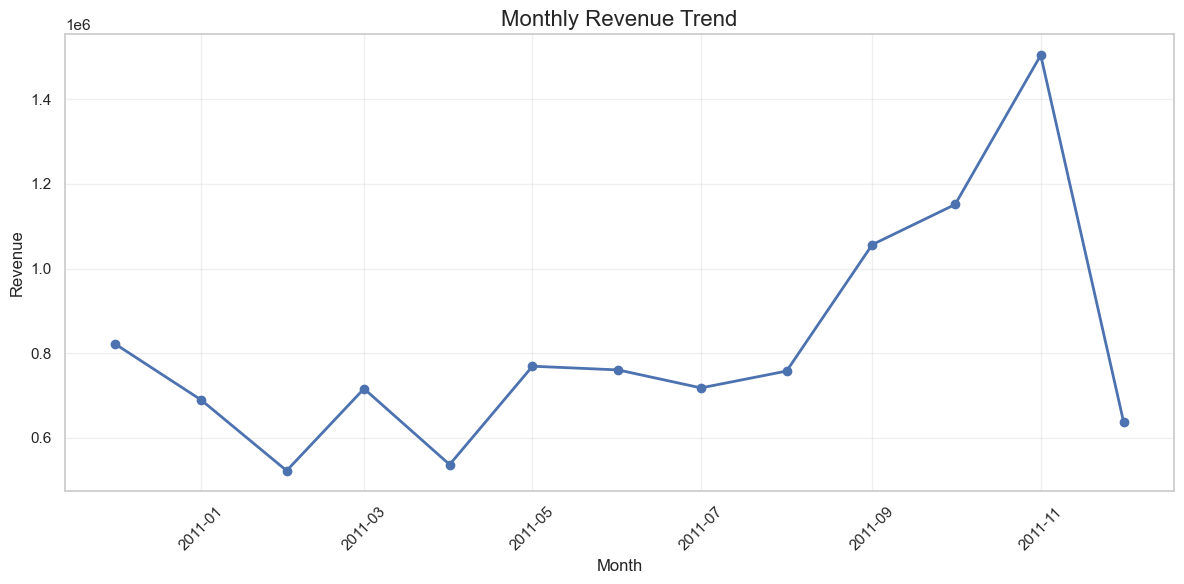

In [16]:

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Observation: Revenue fluctuated during the first eight months of 2011, then increased substantially from September, reaching its highest point in November at approximately 1.50 million. This may indicate stronger seasonal demand toward the year-end shopping period. December revenue is lower, but the dataset ends on 9 December 2011, so it represents an incomplete month.

In [17]:

top_quantity_products = (
    df_sales.groupby(["StockCode", "Description"])["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

print("Top 10 products by quantity sold:")
display(top_quantity_products)


Top 10 products by quantity sold:


,StockCode,Description,Quantity
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
3,85099B,JUMBO BAG RED RETROSPOT,48371
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580
5,22197,POPCORN HOLDER,36749
6,21212,PACK OF 72 RETROSPOT CAKE CASES,36396
7,84879,ASSORTED COLOUR BIRD ORNAMENT,36362
8,23084,RABBIT NIGHT LIGHT,30739
9,22492,MINI PAINT SET VINTAGE,26633


Observation: PAPER CRAFT, LITTLE BIRDIE had the highest recorded quantity sold, at 80,995 units, followed by MEDIUM CERAMIC TOP STORAGE JAR at 78,033 units. WORLD WAR 2 GLIDERS ASSTD DESIGNS ranked third, with 54,951 units. These products may represent strong demand, although unusually large quantities should be investigated to determine whether they reflect bulk orders or exceptional transactions.

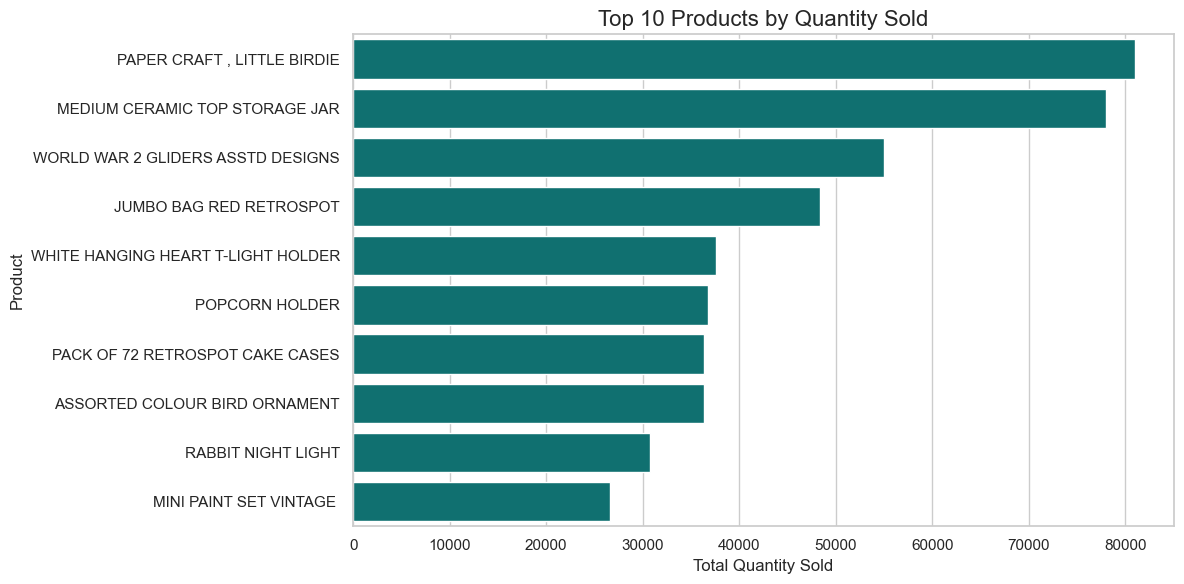

In [18]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_quantity_products,
    x="Quantity",
    y="Description",
    color="teal"
)

plt.title("Top 10 Products by Quantity Sold", fontsize=16)
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [19]:

# Calculate revenue for each invoice
order_revenue = (
    df_sales.groupby("InvoiceNo")["Revenue"]
    .sum()
)

# Calculate Average Order Value
aov = order_revenue.mean()

print("Total number of orders:", len(order_revenue))
print("Average Order Value:", round(aov, 2))
print("Median Order Value:", round(order_revenue.median(), 2))


Total number of orders: 19960
Average Order Value: 533.17
Median Order Value: 303.3


Observation: The dataset contains 19,960 invoices, with an average order value of 533.17 and a median order value of 303.30 (in the dataset's monetary units). Since the mean is considerably higher than the median, some high-value orders may be pulling the average upward. The median therefore provides a useful complementary measure of typical order value.

In [20]:

# Exclude transactions without a customer ID
customer_sales = df_sales.dropna(subset=["CustomerID"]).copy()

# Calculate total revenue per customer
top_customers = (
    customer_sales.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

print("Top 10 customers by revenue:")
display(top_customers)


Top 10 customers by revenue:


,CustomerID,Revenue
0,14646.0,280206.02
1,18102.0,259657.30
2,17450.0,194390.79
3,16446.0,168472.50
4,14911.0,143711.17
5,12415.0,124914.53
6,14156.0,117210.08
7,17511.0,91062.38
8,16029.0,80850.84
9,12346.0,77183.60


Observation: Customer 14646 generated the highest recorded revenue at 280,206.02, followed by Customer 18102 at 259,657.30 and Customer 17450 at 194,390.79. These customers may be important high-value accounts. The business could investigate their purchasing frequency and product preferences to develop customer-retention strategies.

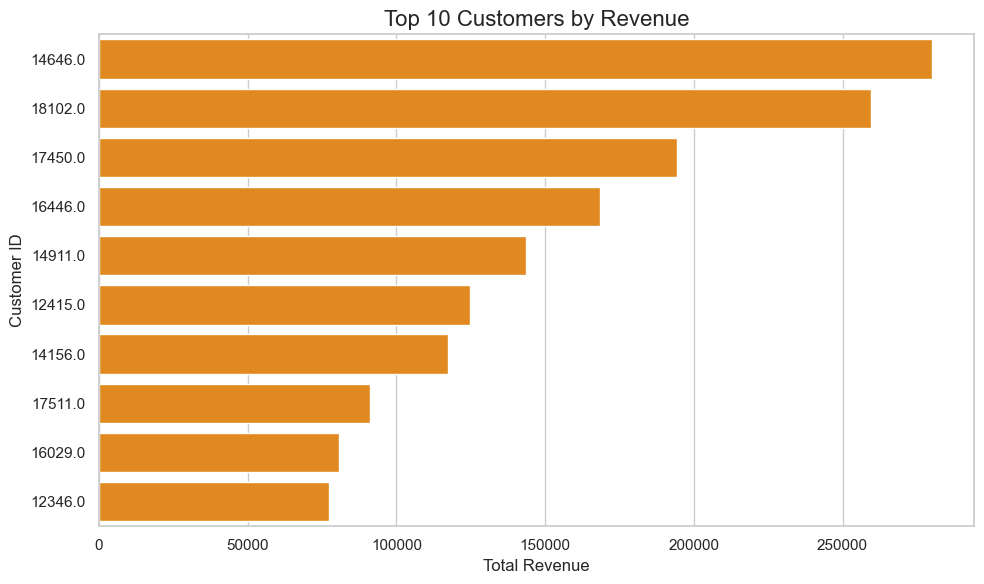

In [22]:

# Treat customer IDs as categories, not numerical values
top_customers["CustomerID"] = (
    top_customers["CustomerID"].astype(str)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_customers,
    x="Revenue",
    y="CustomerID",
    color="darkorange"
)

plt.title("Top 10 Customers by Revenue", fontsize=16)
plt.xlabel("Total Revenue")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()


Customer 14646 generated the highest revenue (280,206.02), followed by Customer 18102 (259,657.30). The concentration of revenue among a small group of customers suggests that retaining high-value customers could be important for the business.

In [23]:

# Summary statistics for quantities and unit prices
print("Quantity summary:")
display(df_sales["Quantity"].describe())

print("\nUnit price summary:")
display(df_sales["UnitPrice"].describe())


Quantity summary:


count    524878.000000
mean         10.616600
std         156.280031
min           1.000000
25%           1.000000
50%           4.000000
75%          11.000000
max       80995.000000
Name: Quantity, dtype: float64


Unit price summary:


count    524878.000000
mean          3.922573
std          36.093028
min           0.001000
25%           1.250000
50%           2.080000
75%           4.130000
max       13541.330000
Name: UnitPrice, dtype: float64

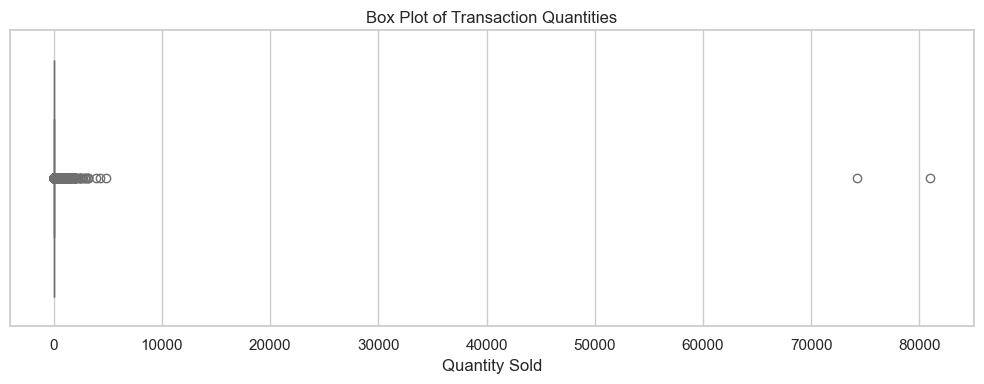

In [24]:

plt.figure(figsize=(10, 4))

sns.boxplot(x=df_sales["Quantity"], color="skyblue")

plt.title("Box Plot of Transaction Quantities")
plt.xlabel("Quantity Sold")
plt.tight_layout()
plt.show()


In [25]:

# Display the 10 transactions with the largest quantities
large_quantity_transactions = (
    df_sales.nlargest(10, "Quantity")[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue",
         "InvoiceDate", "CustomerID", "Country"]
    ]
)

display(large_quantity_transactions)


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,InvoiceDate,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,2011-12-09 09:15:00,16446.0,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,2011-01-18 10:01:00,12346.0,United Kingdom
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,1008.00,2011-10-27 12:26:00,12901.0,United Kingdom
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,3096.00,2011-05-27 10:52:00,13135.0,United Kingdom
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,3202.92,2011-02-22 10:43:00,18087.0,United Kingdom
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,191.16,2011-07-19 17:04:00,14609.0,United Kingdom
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,2011-01-11 12:55:00,15749.0,United Kingdom
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,2011-04-18 13:20:00,15749.0,United Kingdom
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32,960.00,2011-11-02 11:24:00,16308.0,United Kingdom
4945,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,518.40,2010-12-02 17:38:00,16754.0,United Kingdom


In [26]:

# Display the 10 transactions with the highest unit prices
high_price_transactions = (
    df_sales.nlargest(10, "UnitPrice")[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue",
         "InvoiceDate", "CustomerID", "Country"]
    ]
)

display(high_price_transactions)


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,InvoiceDate,CustomerID,Country
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33,2010-12-07 15:08:00,NaN,United Kingdom
299982,A563185,B,Adjust bad debt,1,11062.06,11062.06,2011-08-12 14:50:00,NaN,United Kingdom
173382,551697,POST,POSTAGE,1,8142.75,8142.75,2011-05-03 13:46:00,16029.0,United Kingdom
297723,562955,DOT,DOTCOM POSTAGE,1,4505.17,4505.17,2011-08-11 10:14:00,NaN,United Kingdom
268028,560373,M,Manual,1,4287.63,4287.63,2011-07-18 12:30:00,NaN,United Kingdom
422351,573077,M,Manual,1,4161.06,4161.06,2011-10-27 14:13:00,12536.0,France
422376,573080,M,Manual,1,4161.06,4161.06,2011-10-27 14:20:00,12536.0,France
406406,571751,M,Manual,1,3949.32,3949.32,2011-10-19 11:18:00,12744.0,Singapore
374542,569382,M,Manual,1,3155.95,3155.95,2011-10-03 16:44:00,15502.0,United Kingdom
347948,567353,M,Manual,1,2653.95,2653.95,2011-09-19 16:14:00,NaN,Hong Kong


In [27]:

# Count how often each product appears in sales records
top_frequent_products = (
    df_sales["Description"]
    .value_counts()
    .head(10)
    .reset_index()
)

top_frequent_products.columns = ["Product", "Transaction Lines"]

print("Top 10 most frequently recorded products:")
display(top_frequent_products)


Top 10 most frequently recorded products:


,Product,Transaction Lines
0,WHITE HANGING HEART T-LIGHT HOLDER,2311
1,JUMBO BAG RED RETROSPOT,2109
2,REGENCY CAKESTAND 3 TIER,2007
3,PARTY BUNTING,1699
4,LUNCH BAG RED RETROSPOT,1581
5,ASSORTED COLOUR BIRD ORNAMENT,1476
6,SET OF 3 CAKE TINS PANTRY DESIGN,1392
7,PACK OF 72 RETROSPOT CAKE CASES,1352
8,LUNCH BAG BLACK SKULL.,1301
9,NATURAL SLATE HEART CHALKBOARD,1255


Observation: WHITE HANGING HEART T-LIGHT HOLDER appeared most frequently (2,311 transaction lines), followed by JUMBO BAG RED RETROSPOT (2,109) and REGENCY CAKESTAND 3 TIER (2,007). These products may have consistent customer demand. Transaction-line frequency differs from total quantity sold and total revenue, so all three measures should be considered when evaluating product performance.

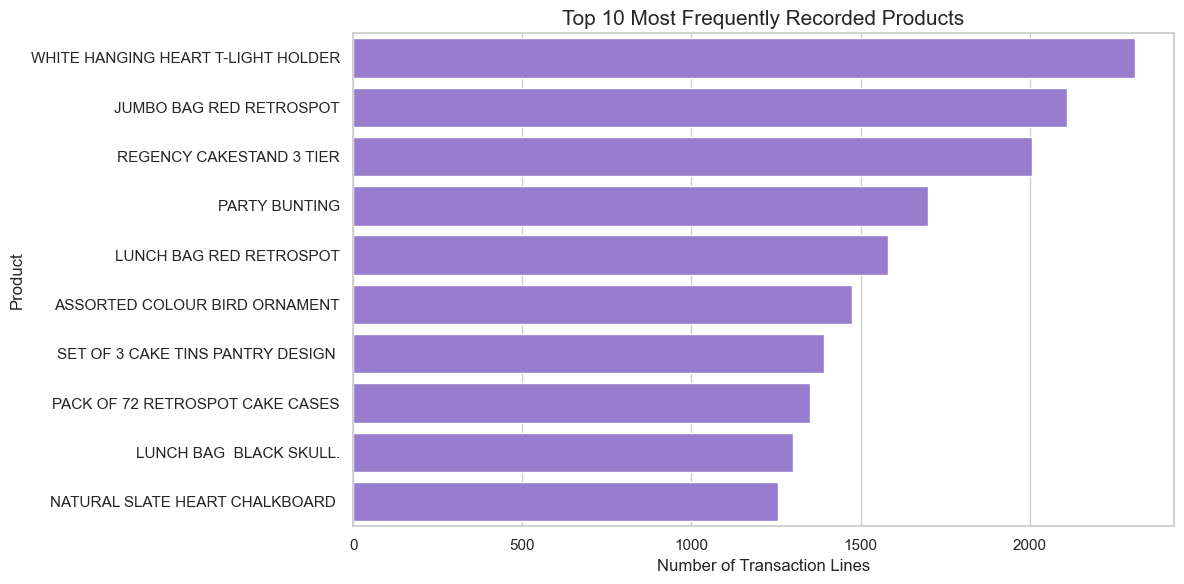

In [28]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_frequent_products,
    x="Transaction Lines",
    y="Product",
    color="mediumpurple"
)

plt.title("Top 10 Most Frequently Recorded Products", fontsize=15)
plt.xlabel("Number of Transaction Lines")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


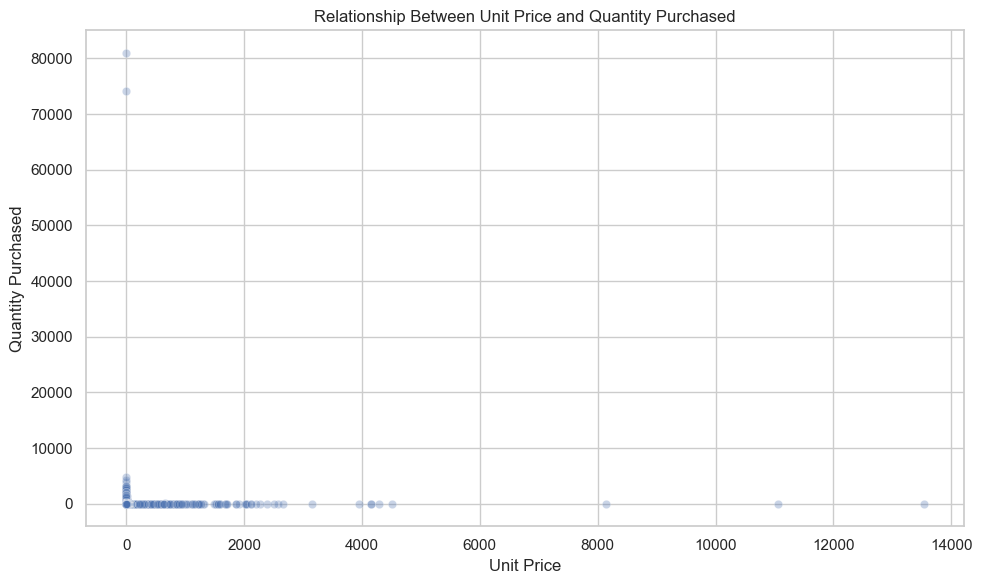

In [29]:

# Explore the relationship between unit price and quantity
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_sales,
    x="UnitPrice",
    y="Quantity",
    alpha=0.3
)

plt.title("Relationship Between Unit Price and Quantity Purchased")
plt.xlabel("Unit Price")
plt.ylabel("Quantity Purchased")
plt.tight_layout()
plt.show()


Observation: The scatter plot shows a highly concentrated distribution of transactions at relatively low unit prices and quantities. A small number of extreme values distort the overall scale. We need to examine the main distribution separately before drawing conclusions about the relationship between price and quantity.

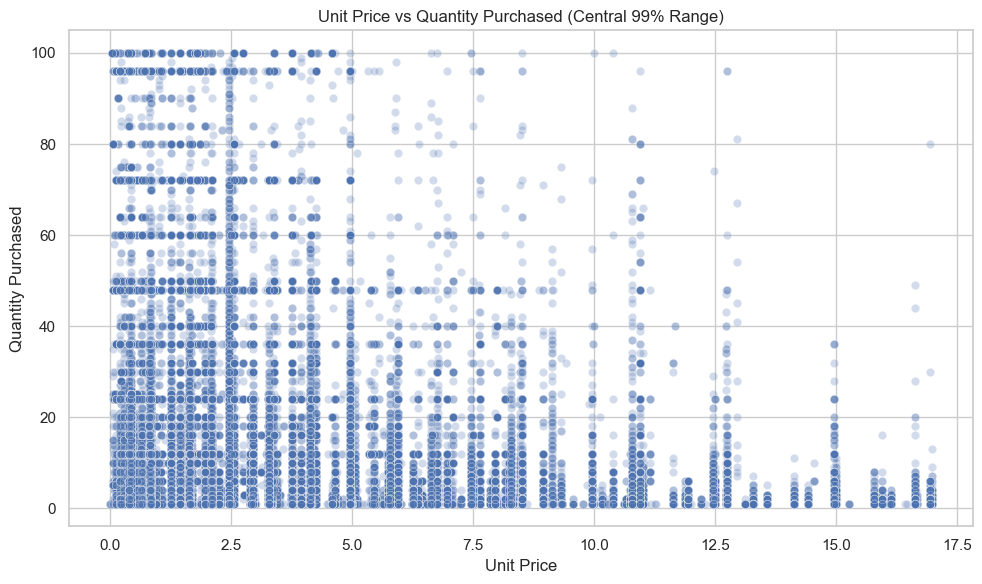

Unit price display limit: 16.98
Quantity display limit: 100.0
Transactions displayed: 514959


In [30]:

# Calculate 99th percentile limits
price_limit = df_sales["UnitPrice"].quantile(0.99)
quantity_limit = df_sales["Quantity"].quantile(0.99)

# Filter only for visualization
df_scatter = df_sales[
    (df_sales["UnitPrice"] <= price_limit)
    & (df_sales["Quantity"] <= quantity_limit)
]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_scatter,
    x="UnitPrice",
    y="Quantity",
    alpha=0.25
)

plt.title("Unit Price vs Quantity Purchased (Central 99% Range)")
plt.xlabel("Unit Price")
plt.ylabel("Quantity Purchased")
plt.tight_layout()
plt.show()

print("Unit price display limit:", round(price_limit, 2))
print("Quantity display limit:", round(quantity_limit, 2))
print("Transactions displayed:", len(df_scatter))


Most transactions involve relatively small quantities, particularly at lower unit prices. Larger quantities appear at several price levels, but the scatter plot alone does not establish a strong relationship between unit price and quantity. A correlation analysis will help quantify the linear relationship.

In [31]:

# Calculate Pearson correlation
price_quantity_corr = df_sales[
    ["UnitPrice", "Quantity"]
].corr().iloc[0, 1]

print(
    "Correlation between unit price and quantity:",
    round(price_quantity_corr, 4)
)


Correlation between unit price and quantity: -0.0038


Observation: The Pearson correlation between unit price and quantity purchased is −0.0038, indicating virtually no linear relationship between these variables across the selected sales transactions. This suggests that unit price alone does not explain the quantity purchased. However, this does not rule out nonlinear relationships or differences between individual products.

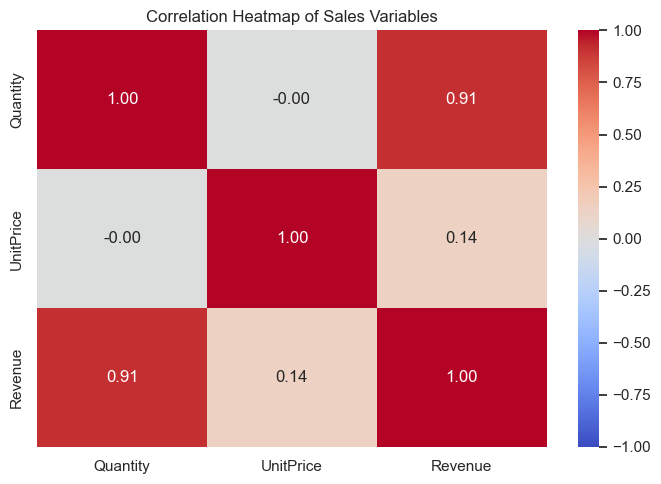

In [32]:

# Select numerical variables for correlation analysis
numeric_cols = [
    "Quantity",
    "UnitPrice",
    "Revenue"
]

correlation_matrix = df_sales[numeric_cols].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Sales Variables")
plt.tight_layout()
plt.show()


Observation: Quantity and revenue have a strong positive correlation of 0.91, while unit price and quantity have virtually no linear correlation (−0.0038). Unit price and revenue have a weak positive correlation of 0.14. The strong quantity–revenue relationship is expected because revenue is calculated as quantity multiplied by unit price. These correlations describe associations, not causal relationships.

In [33]:

# Identify cancellation invoice numbers
is_cancelled = (
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
)

# Count unique invoices
total_invoices = df_clean["InvoiceNo"].nunique()

cancelled_invoices = df_clean.loc[
    is_cancelled, "InvoiceNo"
].nunique()

# Calculate cancellation percentage
cancellation_percentage = (
    cancelled_invoices / total_invoices
) * 100

print("Total unique invoices:", total_invoices)
print("Unique cancelled invoices:", cancelled_invoices)
print(
    "Cancellation invoice percentage:",
    round(cancellation_percentage, 2), "%"
)


Total unique invoices: 24446
Unique cancelled invoices: 3836
Cancellation invoice percentage: 15.69 %


Observation: Of the 24,446 unique invoice numbers, 3,836 were marked as cancellations, representing 15.69%. This indicates that cancellations are a meaningful part of the transaction history and should be considered when evaluating sales performance. This is an invoice-based measure, not a percentage of revenue lost.

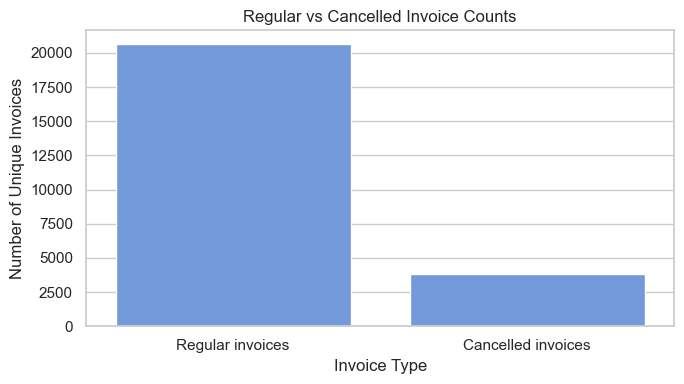

In [34]:

cancellation_labels = ["Regular invoices", "Cancelled invoices"]
cancellation_counts = [
    total_invoices - cancelled_invoices,
    cancelled_invoices
]

plt.figure(figsize=(7, 4))
sns.barplot(
    x=cancellation_labels,
    y=cancellation_counts,
    color="cornflowerblue"
)

plt.title("Regular vs Cancelled Invoice Counts")
plt.xlabel("Invoice Type")
plt.ylabel("Number of Unique Invoices")
plt.tight_layout()
plt.show()


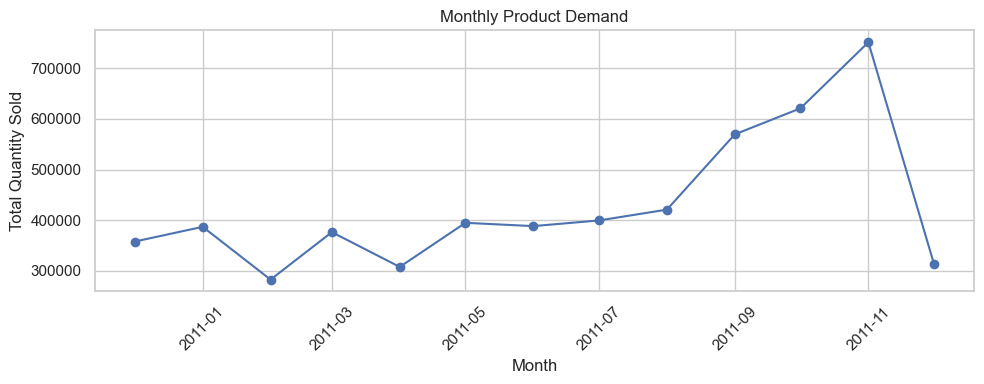

In [35]:

# Monthly quantity sold
monthly_quantity = (
    df_sales.groupby(df_sales["InvoiceDate"].dt.to_period("M"))["Quantity"]
    .sum()
    .reset_index()
)

monthly_quantity["InvoiceDate"] = (
    monthly_quantity["InvoiceDate"].dt.to_timestamp()
)

plt.figure(figsize=(10, 4))
plt.plot(
    monthly_quantity["InvoiceDate"],
    monthly_quantity["Quantity"],
    marker="o"
)

plt.title("Monthly Product Demand")
plt.xlabel("Month")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Product quantities increased substantially from September to November 2011, reaching a peak in November. December shows a decline, but the dataset ends on 9 December, so that month is incomplete. This suggests a possible year-end seasonal pattern that would need validation with additional years of data.

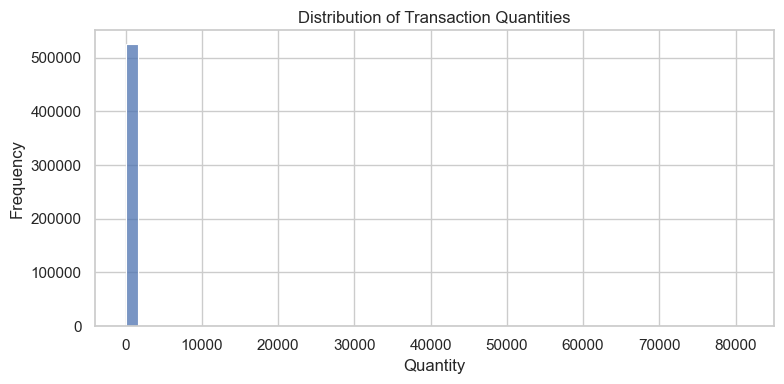

In [36]:

plt.figure(figsize=(8, 4))

sns.histplot(
    data=df_sales,
    x="Quantity",
    bins=50
)

plt.title("Distribution of Transaction Quantities")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


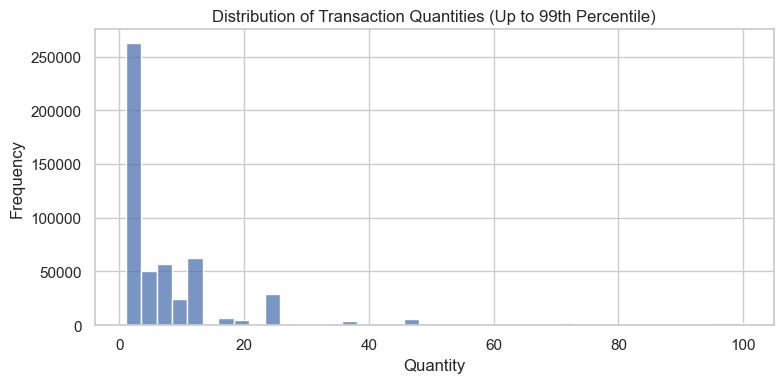

99th percentile quantity: 100.0


In [37]:

quantity_99 = df_sales["Quantity"].quantile(0.99)

plt.figure(figsize=(8, 4))

sns.histplot(
    data=df_sales[df_sales["Quantity"] <= quantity_99],
    x="Quantity",
    bins=40
)

plt.title("Distribution of Transaction Quantities (Up to 99th Percentile)")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("99th percentile quantity:", quantity_99)


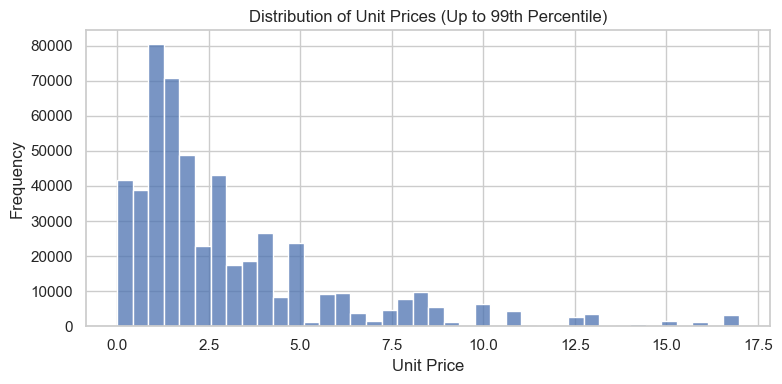

99th percentile unit price: 16.98


In [38]:

price_99 = df_sales["UnitPrice"].quantile(0.99)

plt.figure(figsize=(8, 4))

sns.histplot(
    data=df_sales[df_sales["UnitPrice"] <= price_99],
    x="UnitPrice",
    bins=40
)

plt.title("Distribution of Unit Prices (Up to 99th Percentile)")
plt.xlabel("Unit Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("99th percentile unit price:", round(price_99, 2))


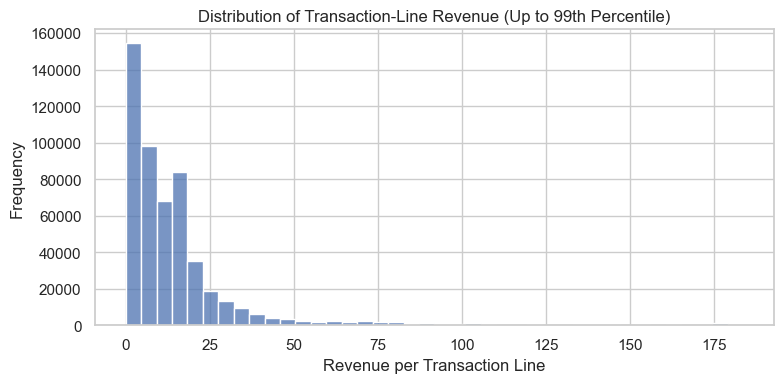

99th percentile line revenue: 183.6


In [39]:

revenue_99 = df_sales["Revenue"].quantile(0.99)

plt.figure(figsize=(8, 4))

sns.histplot(
    data=df_sales[df_sales["Revenue"] <= revenue_99],
    x="Revenue",
    bins=40
)

plt.title("Distribution of Transaction-Line Revenue (Up to 99th Percentile)")
plt.xlabel("Revenue per Transaction Line")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("99th percentile line revenue:", round(revenue_99, 2))


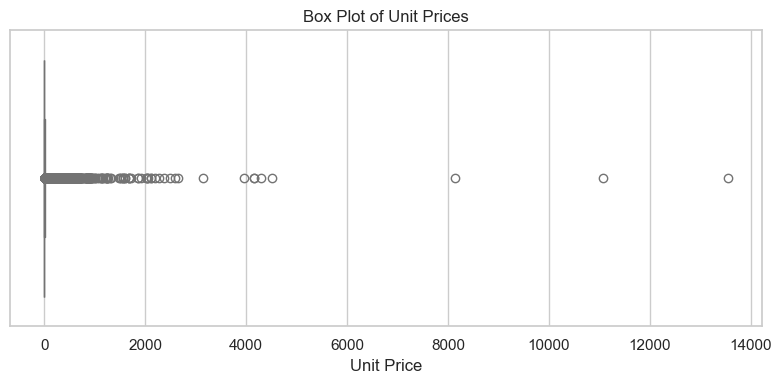

In [40]:

plt.figure(figsize=(8, 4))

sns.boxplot(
    x=df_sales["UnitPrice"],
    color="lightgreen"
)

plt.title("Box Plot of Unit Prices")
plt.xlabel("Unit Price")
plt.tight_layout()
plt.show()


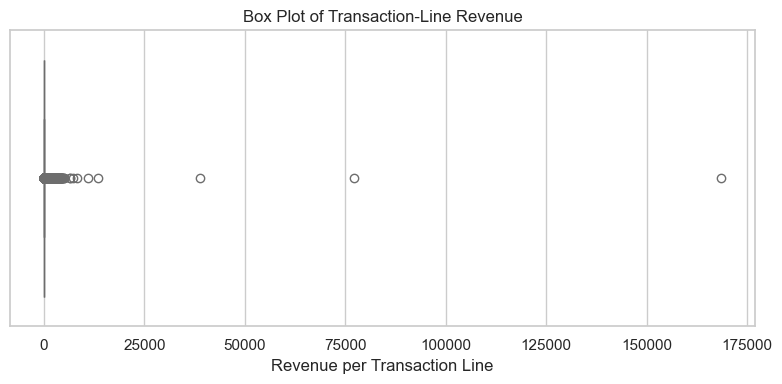

In [41]:

plt.figure(figsize=(8, 4))

sns.boxplot(
    x=df_sales["Revenue"],
    color="salmon"
)

plt.title("Box Plot of Transaction-Line Revenue")
plt.xlabel("Revenue per Transaction Line")
plt.tight_layout()
plt.show()


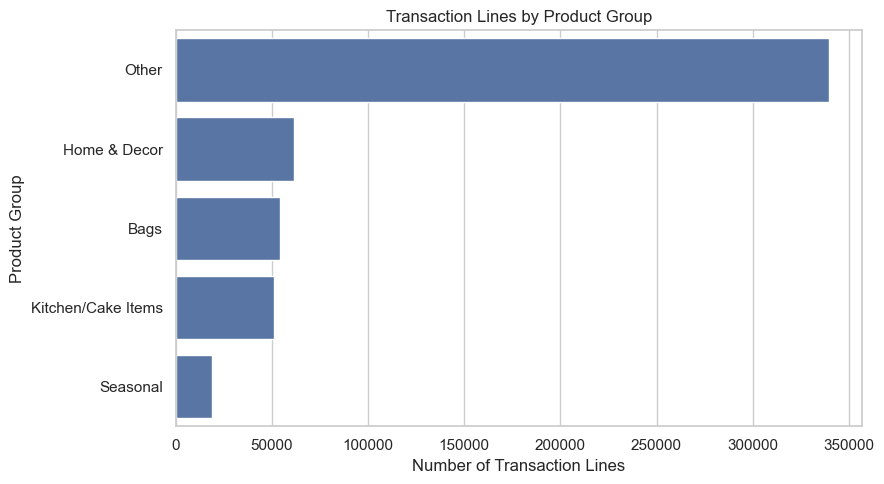

In [42]:

# Extract product category from the product description
category_keywords = {
    "BAGS": "Bags",
    "BAG": "Bags",
    "CAKE": "Kitchen/Cake Items",
    "TIN": "Kitchen/Cake Items",
    "HEART": "Home & Decor",
    "LIGHT": "Home & Decor",
    "CHRISTMAS": "Seasonal",
    "JUMBO": "Bags"
}

def categorize_product(description):
    text = str(description).upper()
    for keyword, category in category_keywords.items():
        if keyword in text:
            return category
    return "Other"

df_sales["ProductGroup"] = df_sales["Description"].apply(
    categorize_product
)

plt.figure(figsize=(9, 5))
sns.countplot(
    data=df_sales,
    y="ProductGroup",
    order=df_sales["ProductGroup"].value_counts().index
)

plt.title("Transaction Lines by Product Group")
plt.xlabel("Number of Transaction Lines")
plt.ylabel("Product Group")
plt.tight_layout()
plt.show()


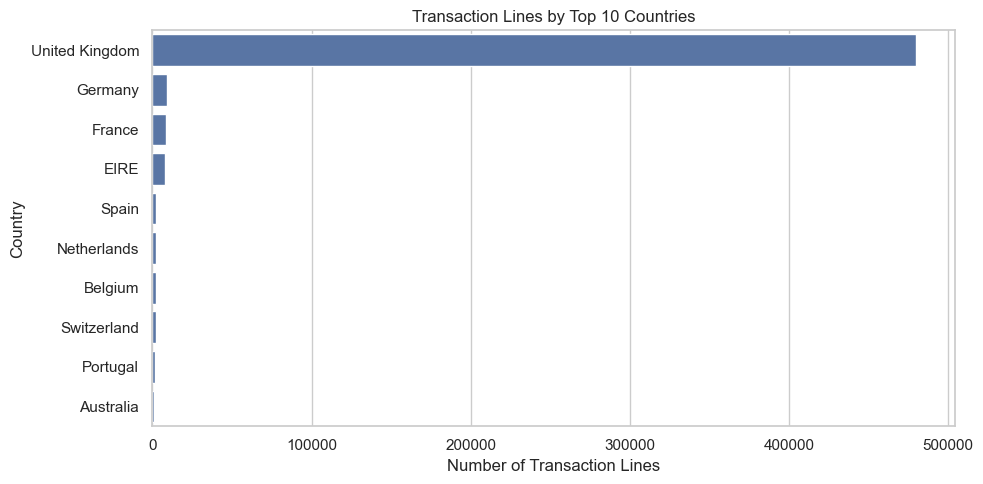

In [43]:

top_10_countries = df_sales["Country"].value_counts().head(10).index

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_sales[df_sales["Country"].isin(top_10_countries)],
    y="Country",
    order=top_10_countries
)

plt.title("Transaction Lines by Top 10 Countries")
plt.xlabel("Number of Transaction Lines")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


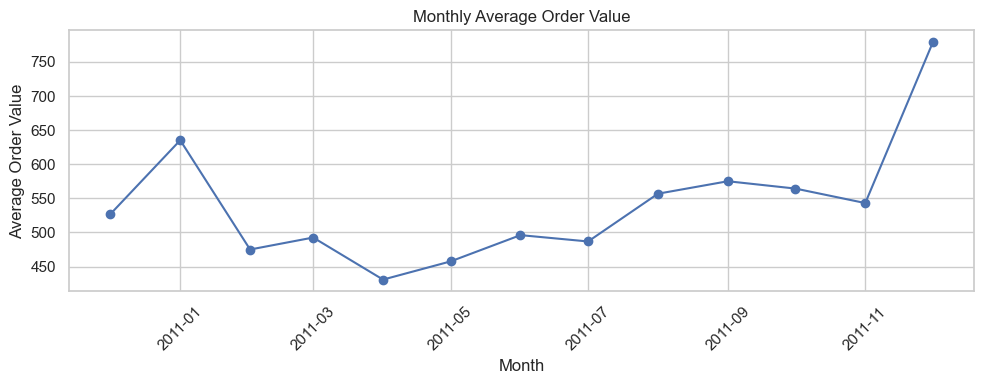

In [44]:

# Calculate average order value for each month
monthly_aov = (
    df_sales.groupby([
        df_sales["InvoiceDate"].dt.to_period("M"),
        "InvoiceNo"
    ])["Revenue"]
    .sum()
    .groupby(level=0)
    .mean()
    .reset_index(name="AverageOrderValue")
)

monthly_aov["InvoiceDate"] = (
    monthly_aov["InvoiceDate"].dt.to_timestamp()
)

plt.figure(figsize=(10, 4))
plt.plot(
    monthly_aov["InvoiceDate"],
    monthly_aov["AverageOrderValue"],
    marker="o"
)

plt.title("Monthly Average Order Value")
plt.xlabel("Month")
plt.ylabel("Average Order Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [45]:

print("Remaining duplicate rows:", df_clean.duplicated().sum())
print("Missing product descriptions:", df_clean["Description"].isna().sum())
print("Missing customer IDs:", df_clean["CustomerID"].isna().sum())
print("Invalid non-positive prices:", (df_clean["UnitPrice"] <= 0).sum())
print("Negative quantity rows:", (df_clean["Quantity"] < 0).sum())


Remaining duplicate rows: 0
Missing product descriptions: 0
Missing customer IDs: 133583
Invalid non-positive prices: 1058
Negative quantity rows: 9725


## Key Findings — E-Commerce Sales & Customer Behavior Analysis

1. Revenue performance: The United Kingdom generated approximately 9.00 million in revenue, making it the dominant market in the dataset.
2. Product revenue: DOTCOM POSTAGE ranked first by recorded revenue, followed by REGEnCY CAKESTAND 3 TIER and PAPER CRAFT, LITTLE BIRDIE. Postage and service entries should be separated from merchandise for a more meaningful product ranking.
3. Product demand: PAPER CRAFT, LITTLE BIRDIE recorded the highest quantity sold, at 80,995 units. Such unusually large orders require further investigation.
4. Monthly trends: Revenue and quantities increased substantially from September to November 2011. December is incomplete because the dataset ends on 9 December.
5. Order value: Average order value was 533.17, while the median was 303.30, suggesting that high-value orders influence the mean.
6. Customer behaviour: Customer 14646 generated the highest recorded customer revenue, at 280,206.02.
7. Cancellations: Cancelled invoice numbers represented 15.69% of unique invoice numbers under the chosen definition.
8. Price and quantity: The Pearson correlation was −0.0038, indicating virtually no linear relationship between unit price and quantity across the analysed sales lines.
9. Data quality: Exact duplicates and missing product descriptions were removed. Missing customer IDs, negative quantities and non-positive prices remain documented for appropriate analysis.

### Business Recommendations

- Develop customer-retention strategies for high-value customers.
- Investigate opportunities to grow sales outside the UK.
- Plan inventory and promotional campaigns around the observed September–November increase.
- Analyse cancellations and returns separately to understand their financial impact.
- Exclude postage, fees and manual adjustments when ranking merchandise products.
- Investigate extreme quantities and prices before treating them as errors.

### Limitations

This dataset covers approximately one year, and December 2011 is incomplete. The analysis is descriptive and does not establish causation. Missing customer IDs limit customer-level analysis, and returns and cancellations require separate treatment for accurate net revenue calculations.